In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from pathlib import Path

In [6]:
from pyMoove import load_processed_dataset, plot_replacement_example, build_feature_table, calculate_bin_position_statistics
from pyMoove.preprocessing import build_gos_event_table
from pyMoove import io, plotting, calculations, cleaning, statistics, interaction_detection
from pyMoove.models import make_logistic_regression_model, make_random_forest_model, make_mlp_model, make_hist_gradient_boosting_model
from pyMoove.evaluation import evaluate_binary_classifier, plot_confusion_matrix, plot_precision_recall_curve, plot_roc_curve
from scripts.zone_info import get_zone_info


In [19]:
DATA_DIR = Path("data")
data = load_processed_dataset(DATA_DIR)
zones_path = DATA_DIR / "zone_info.csv"
zones = get_zone_info(zones_path)

# Calculate statistics for all feeding bins
#bins = sorted(data["feeding"]["bin"].dropna().unique())
#bin_statistics = calculations.calculate_bin_position_statistics(data, bins, outlier_confidence=0.9999)
#bin_statistics.to_parquet(bin_statistics_path, index=False)

# Save results to Parquet
bin_statistics_path = DATA_DIR / "bin_position_stats.parquet"
bin_statistics = io.load_bin_stats_parquet(bin_statistics_path)

# Data cleaning that removes all replacement events where there is only positional data on one of the cows
replacements = data['replacements']
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)
replacements = cleaning.filter_replacement_events(replacements, stats)
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)

# Remove outliers. Parameters has been set based on based on manual inspection of outlier data. 
outliers_mask = (stats['actor_bin_min_m'] > 1) | (stats['reactor_bin_min_m'] > 1.11) | (stats['cow_min_m'] > 2.136)
replacements = replacements[~outliers_mask.to_numpy()]
print(f"\nTotal replacement events after removing outliers: {len(replacements)}\n")
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)


Loaded dataset in folder: data
  positions Memory: 571.74 MiB
  feeding Memory: 0.28 MiB
  replacements Memory: 0.04 MiB
Total memory: 572.06 MiB

Total events before cleaning: 550
Events retained: 470
Events removed: 80

Total replacement events after removing outliers: 431



In [22]:
###########################
# BIN INTERACTION PIPELINE #
###########################

# Detection of gos events
bins = range(1, 11)
# We filter out the specific bins we want to look at
bin_replacements = replacements[replacements['bin'].isin(bins)]
bin_interactions = interaction_detection.detect_bin_interactions(data['positions'], bin_statistics, bins, max_bin_distance=2.0, cooldown=30, bout_interval=23)
# This is needed to ensure non duplicate indices, hopefully Oscar can fix this
bin_interactions = bin_interactions.reset_index(drop=True)

#Statistics about how many interactions and replacements there are as well as how many of the replacements were identified as bin_interaction events (recall)
recall = interaction_detection.check_bin_interactions(bin_replacements, bin_interactions, acceptance_interval=30, cow_role_matters=False, show_detections=False)

# Validation of which gos events are actual replacements or not
# The output is a mask of what bin_interactions are real replacements:
# bin_interactions[label_mask]          - bin interactions that correspond to replacement events
# bin_interactions[~label_mask]         - bin interactions that do NOT correspond to replacement events
label_mask = interaction_detection.validate_bin_interactions(bin_replacements, bin_interactions, acceptance_interval=30)

Actual replacements: 61
Bin interactions: 72085
58 / 61 replacement events were detected

Detected replacements: 72085
Actual replacements: 61
Detected replacements labeled as real: 85
Detected replacements labeled as not real: 72000



In [31]:
gos_events = build_gos_event_table(bin_interactions, data["positions"])

In [36]:
feature_table = build_feature_table(gos_events, bin_statistics)

In [42]:
feature_table[label_mask]

,cow_to_cow_distance_min_m,cow_to_cow_distance_mean_m,cow_to_cow_distance_max_m,cow_to_cow_distance_start_m,cow_to_cow_distance_end_m,cow_to_cow_distance_std_m,cow_1_to_bin_distance_min_m,cow_1_to_bin_distance_mean_m,cow_1_to_bin_distance_max_m,cow_1_to_bin_distance_start_m,...,cow_2_to_bin_distance_end_m,cow_2_to_bin_distance_std_m,cow_1_speed_mean_m_s,cow_1_speed_max_m_s,cow_1_path_length_m,cow_1_net_displacement_m,cow_2_speed_mean_m_s,cow_2_speed_max_m_s,cow_2_path_length_m,cow_2_net_displacement_m
87,0.228849,1.779366,3.565325,1.926461,2.232904,0.781024,1.436062,1.889055,3.787245,1.762389,...,0.705919,0.387715,0.327050,0.910050,7.239643,1.018788,0.303532,0.754139,6.068491,1.007335
456,0.437536,1.261312,2.033364,2.033364,1.499986,0.442832,0.713136,0.994085,1.302890,1.038039,...,2.250539,0.648569,0.244752,0.730360,4.413316,1.894145,0.301376,1.809268,3.614486,2.195498
1278,0.668426,1.611691,2.608737,2.608737,1.421473,0.578608,0.244302,0.621436,1.504672,1.504672,...,1.429667,0.503665,0.230628,1.034859,3.465348,2.563770,0.431277,1.423515,7.503628,1.885359
1403,0.282959,0.972890,1.535660,0.663346,0.282959,0.354665,0.397954,1.040879,1.878322,1.878322,...,0.452107,0.365627,0.241124,0.517946,5.396967,1.496265,0.253422,0.473071,5.149728,0.885255
1406,0.673795,1.704101,2.742175,1.938226,1.974619,0.587501,0.286478,0.643937,1.431347,0.387269,...,1.626331,0.179753,0.172283,0.464833,3.887957,1.500162,0.418196,0.728369,8.579975,0.328906
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60722,1.825248,2.814679,4.360803,2.123499,2.085039,0.772103,0.748288,1.167591,2.324389,0.773777,...,2.714980,0.910481,0.349825,0.812619,8.017177,0.966433,0.446160,0.912372,9.847936,1.214292
66126,0.825550,1.861608,3.323354,1.481869,2.098555,0.684941,0.591635,1.574663,2.702258,0.591635,...,0.396341,0.365003,0.338552,0.801296,7.584224,1.945925,0.324186,0.792187,6.813848,1.238538
66134,1.720310,3.809072,5.138811,1.720310,3.287117,1.035207,1.138966,1.665667,2.476884,1.872648,...,3.938001,0.967565,0.417869,1.094992,8.568665,2.130743,0.508325,1.218771,11.636910,3.495006
67647,0.845529,1.552857,2.325097,0.845529,0.879074,0.448296,0.327965,0.701779,1.362928,0.373542,...,1.067403,0.286959,0.360450,0.645534,8.070296,0.858033,0.217473,0.452430,4.367624,1.421075


In [46]:
feature_table["label"] = 0
feature_table[label_mask] = 1

In [49]:
#creating the training and test data

X = feature_table.drop(columns=["label"])
y_demo = feature_table["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_demo, test_size=0.25, random_state=42, stratify=y_demo
)

In [50]:
#creating models
model_regression = make_logistic_regression_model()
model_forrest = make_random_forest_model()
model_gradient_boosting = make_hist_gradient_boosting_model()
model_mlp = make_mlp_model()

models = {
    "regression": model_regression,
    "random_forest": model_forrest,
    "gradient_boosting": model_gradient_boosting,
    "mlp": model_mlp,
}

In [51]:
#Looping over the models, fiting them to the data and making a prediction. Evaluating them and saving the metrics
positive_label = 1
models_predictions = {}
models_metrics = {}

for name, model in models.items():
    if name == "mlp":
        weights = compute_sample_weight("balanced", y_train)
        model.fit(X_train, y_train, classifier__sample_weight=weights)
    else:
        model.fit(X_train, y_train)

    positive_index = list(model.classes_).index(positive_label)
    models_predictions[name] = model.predict_proba(X_test)[:, positive_index]
    models_metrics[name] = evaluate_binary_classifier(
        y_test, models_predictions[name]
    )

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


In [63]:
y_test.sum()

np.int64(21)

In [53]:
for model in models_metrics:
    print(f"Metrics for {model}:")
    for metric, value in models_metrics[model].items():
        print(f"{metric}: {value:.4f}")
    print()

Metrics for regression:
n_samples: 18022.0000
n_positive: 21.0000
n_negative: 18001.0000
threshold: 0.5000
tn: 18001.0000
fp: 0.0000
fn: 0.0000
tp: 21.0000
precision: 1.0000
recall: 1.0000
specificity: 1.0000
f1: 1.0000
balanced_accuracy: 1.0000
roc_auc: 1.0000
average_precision: 1.0000

Metrics for random_forest:
n_samples: 18022.0000
n_positive: 21.0000
n_negative: 18001.0000
threshold: 0.5000
tn: 18001.0000
fp: 0.0000
fn: 0.0000
tp: 21.0000
precision: 1.0000
recall: 1.0000
specificity: 1.0000
f1: 1.0000
balanced_accuracy: 1.0000
roc_auc: 1.0000
average_precision: 1.0000

Metrics for gradient_boosting:
n_samples: 18022.0000
n_positive: 21.0000
n_negative: 18001.0000
threshold: 0.5000
tn: 18001.0000
fp: 0.0000
fn: 0.0000
tp: 21.0000
precision: 1.0000
recall: 1.0000
specificity: 1.0000
f1: 1.0000
balanced_accuracy: 1.0000
roc_auc: 1.0000
average_precision: 1.0000

Metrics for mlp:
n_samples: 18022.0000
n_positive: 21.0000
n_negative: 18001.0000
threshold: 0.5000
tn: 18001.0000
fp: 0.00

In [65]:
gos_events_new = build_gos_event_table(replacements, data["positions"])
feature_table = build_feature_table(gos_events_new, bin_statistics)


In [79]:
regression_predict = models["mlp"].predict_proba(feature_table)

In [80]:
np.sum(regression_predict[:, 0] > 0.5)/len(regression_predict)

np.float64(1.0)

In [88]:
models

{'regression': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler()),
                 ('classifier',
                  LogisticRegression(class_weight='balanced', max_iter=1000,
                                     random_state=0))]),
 'random_forest': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('classifier',
                  RandomForestClassifier(class_weight='balanced',
                                         n_estimators=200, n_jobs=-1,
                                         random_state=0))]),
 'gradient_boosting': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('classifier',
                  HistGradientBoostingClassifier(class_weight='balanced',
                                                 l2_regularization=1.0,
                                                 max_iter=200,
                                                 random_state=0))]),
 'ml

In [86]:
import numpy as np

In [89]:
feature_importance = models["regression"].named_steps["classifier"].coef_[0]
classifier = model["regression"].named_steps["classifier"]

feature_importance[name] = pd.Series(
    np.abs(classifier.coef_[0]),
    index=feature_table.columns,
    name=name,
).sort_values(ascending=False)

KeyError: 'regression'

In [90]:
from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np

feature_importances = {}
feature_names = X_train.columns

for name, model in models.items():
    classifier = model.named_steps["classifier"]

    if name in {"regression"}:
        if name == "regression":
            # Absolute coefficients provide relative feature importance
            values = np.abs(classifier.coef_[0])
        else:
            values = classifier.feature_importances_

        feature_importances[name] = pd.Series(
            values,
            index=feature_names,
            name=name,
        ).sort_values(ascending=False)

    elif name == "mlp":
        # Permutation importance is the model-agnostic way to assess MLP features
        result = permutation_importance(
            model,
            X_test,
            y_test,
            scoring="average_precision",
            n_repeats=10,
            random_state=42,
            n_jobs=-1,
        )

        feature_importances[name] = pd.Series(
            result.importances_mean,
            index=feature_names,
            name=name,
        ).sort_values(ascending=False)

importance_table = pd.concat(feature_importances.values(), axis=1)
importance_table

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.02s - Debugger warning: It seems that frozen modules are being used, which may
0

,regression,mlp
cow_2_speed_mean_m_s,1.583884,2.065743e-01
cow_1_speed_mean_m_s,1.416531,1.362606e-03
cow_1_path_length_m,1.081250,-2.220446e-16
cow_2_path_length_m,1.074071,4.957651e-03
cow_2_to_bin_distance_std_m,0.493599,-2.220446e-16
cow_to_cow_distance_max_m,0.422576,-2.220446e-16
cow_1_to_bin_distance_std_m,0.422045,-2.220446e-16
cow_1_to_bin_distance_max_m,0.381805,1.331958e-02
cow_2_to_bin_distance_max_m,0.332713,-2.220446e-16
cow_to_cow_distance_mean_m,0.282271,-2.220446e-16


<Axes: xlabel='False Positive Rate (Positive label: 1)', ylabel='True Positive Rate (Positive label: 1)'>

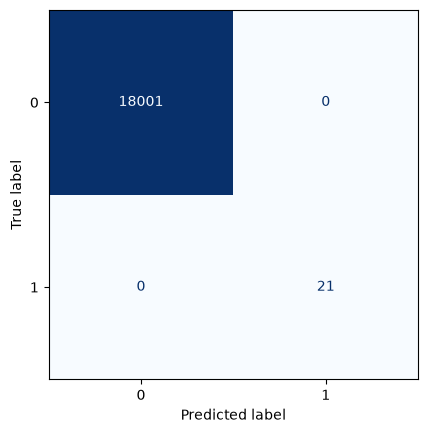

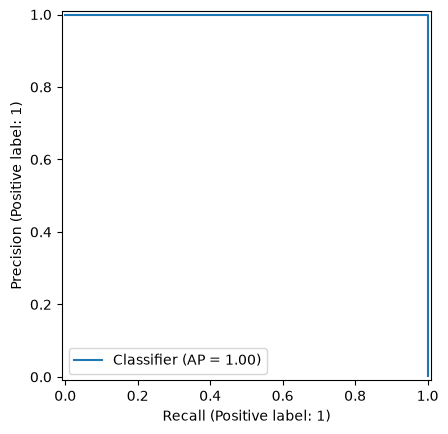

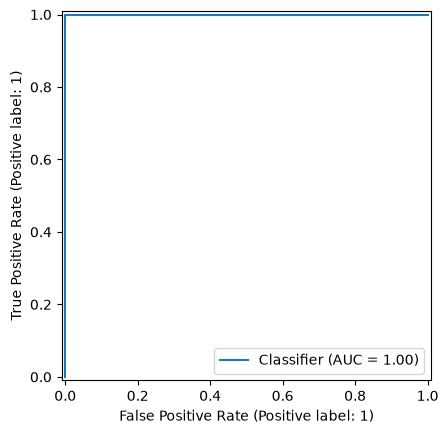

In [56]:
#plotting evaluation

plot_confusion_matrix(y_test, np.round(models_predictions["random_forest"]))
plot_precision_recall_curve(y_test, models_predictions["random_forest"])
#plot_roc_curve(y_test, models_predictions["random_forest"])

In [ ]:
#CREATING SOME DUMMY GOS EVENTS

from itertools import combinations
import pandas as pd


def build_gos_event_examples(positions, max_events=100, window_size=10):
    columns = ["IDs", "datetime", "x", "y"]
    has_velocity = "velocity" in positions.columns
    if has_velocity:
        columns.append("velocity")

    data = positions[columns].dropna(
        subset=["IDs", "datetime", "x", "y"]
    )
    data = (
        data.sort_values("datetime")
        .drop_duplicates(["IDs", "datetime"], keep="last")
    )

    cow_ids = sorted(data["IDs"].unique(), key=str)
    events = []

    for cow_1_id, cow_2_id in combinations(cow_ids, 2):
        cow_1 = data.loc[data["IDs"] == cow_1_id].drop(columns="IDs")
        cow_2 = data.loc[data["IDs"] == cow_2_id].drop(columns="IDs")

        pair = cow_1.merge(
            cow_2,
            on="datetime",
            suffixes=("_1", "_2"),
        ).sort_values("datetime")

        if len(pair) < window_size:
            continue

        pair = pair.iloc[:window_size]
        event = {
            "cow_1_id": cow_1_id,
            "cow_2_id": cow_2_id,
            "timestamps": pair["datetime"].tolist(),
            "positions": [
                pair[["x_1", "y_1"]].astype(float).values.tolist(),
                pair[["x_2", "y_2"]].astype(float).values.tolist(),
            ],
        }

        if has_velocity:
            event["velocities"] = [
                pair["velocity_1"].tolist(),
                pair["velocity_2"].tolist(),
            ]

        events.append(event)
        if len(events) >= max_events:
            break

    return events
